# Derivados Lineales

## FRA
Un Forward Rate Agreement (FRA) es un contrato que fija hoy una tasa de interés $K$ para un periodo futuro $[T_1,T_2]$. Las partes intercambian la diferencia entre los intereses calculados a la tasa fija y a la tasa de referencia sobre un nominal $N$. El nominal sirve como base de cálculo y no se intercambia.

Sea $\delta$ la fracción de año del periodo $[T_1,T_2]$ y $L_{T_1}$ la tasa de referencia que se observa en $T_1$ para ese periodo. Para la posición que paga fijo y recibe variable, el payoff al final del periodo es

$$\boxed{X_{T_2}=N\delta(L_{T_1}-K)}$$


### Valuación en una sola curva
Sea  $B(t,T) el precio en t de un bono cupón cero que paga una unidad en T. Suponemos que la tasa de referencia $L_{T_1}$ es la tasa simple de la misma curva que usamos para descontar. En Particular 
$$B(T_1,T_2) = \frac{1}{1+\delta L_{T_1}}$$

Para $t<T_1$, consideremos dos portafolios:

A: Un FRA que paga fijo y recibe variable, más $N(1+\delta K)$ bonos cupón cero con vencimiento en $T_2$.

$$A = f_t+N(1+\delta K)B(t,T_2)$$

B: N bonos cupón cero con vencimiento en $T_1$. En $T_1$, reinvertimos los N que pagan estos bonos hasta $T_2$ a la tasa $L_{T_1}$.

$$ B =  NB(t,T_1) $$

En $T_2$ el portafolio A vale

$$ N\delta(L_{T_1}-K)+N(1+\delta K)=N(1+\delta L_{T_1}) $$

Que es exactamente lo que entrega el portafolio B después de reinvertir. Por ausencia de arbitraje, ambos portafolios tienen el mismo valor en \(t\):

$$f_t+N(1+\delta K)B(t,T_2)=NB(t,T_1)$$

Por tanto, el valor del FRA es
$$\boxed{
f_t=N\left[B(t,T_1)-(1+\delta K)B(t,T_2)\right].
}$$




Tasa forward
La tasa forward $F_t=F(t;T_1,T_2)$ es la tasa fija que hace que un FRA nuevo tenga valor cero. Al sustituir $K=F_t$ y $f_t=0$,

$$(1+\delta F_t)B(t,T_2)=B(t,T_1).$$

$$\boxed{
F_t=\frac{1}{\delta}
\left(\frac{B(t,T_1)}{B(t,T_2)}-1\right).
}$$



In [2]:
def forward_rate(fraccion, b1, b2):
    if fraccion == 0:
        raise ValueError("La fracción no puede ser cero.")

    return 1/fraccion * (b2/b1 - 1)

In [3]:
def precio_fra(nominal, tasa_fija, fraccion, descuento_inicio, descuento_fin):
    """Valor actual de un FRA que paga fijo y recibe variable."""
    return nominal * (
        descuento_inicio - (1 + fraccion * tasa_fija) * descuento_fin
    )


valor = precio_fra(
    nominal=10_000_000,
    tasa_fija=0.08,
    fraccion=90 / 360,
    descuento_inicio=0.98016,
    descuento_fin=0.96,
)

print(f"Valor del FRA: {valor:,.2f} MXN")

Valor del FRA: 9,600.00 MXN


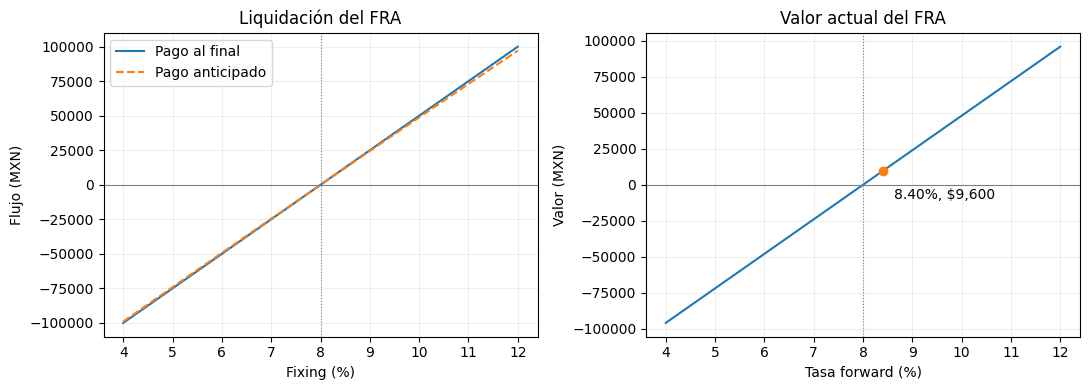

In [4]:
import numpy as np
import matplotlib.pyplot as plt

N = 10_000_000
K = 0.08
delta = 90 / 360
B2 = 0.96

tasas = np.linspace(0.04, 0.12, 201)

# Liquidación para distintos fixings L
flujo_final = N * delta * (tasas - K)
flujo_anticipado = flujo_final / (1 + delta * tasas)

# Valor actual para distintos forwards F_t, manteniendo B2 fijo
B1 = B2 * (1 + delta * tasas)
valores = precio_fra(N, K, delta, B1, B2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(100 * tasas, flujo_final, label="Pago al final")
ax1.plot(100 * tasas, flujo_anticipado, "--", label="Pago anticipado")
ax1.set(title="Liquidación del FRA", xlabel="Fixing (%)", ylabel="Flujo (MXN)")
ax1.legend()

ax2.plot(100 * tasas, valores)
ax2.scatter(8.40, 9_600, color="tab:orange", zorder=3)
ax2.annotate("8.40%, $9,600", (8.40, 9_600),
             xytext=(8, -20), textcoords="offset points")
ax2.set(title="Valor actual del FRA", xlabel="Tasa forward (%)", ylabel="Valor (MXN)")

for ax in (ax1, ax2):
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(100 * K, color="gray", linestyle=":", linewidth=0.8)
    ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

# IRS (Interest Rate Swap)

Un Interest Rate Swap (IRS) de tasa fija contra variable es un contrato en el que dos partes intercambian pagos de intereses en varias fechas. Una parte paga una tasa fija $K$ y la otra paga una tasa de referencia que se fija al inicio de cada periodo. Ambas patas se calculan sobre un nominal $N$, que sirve como base de cálculo y no se intercambia.

Consideremos las fechas

$$ t\leq T_0< t_1< \cdots< T_n$$

donde $T_0$ es el inicio del swap y T_i es la fecha de pago del periodo $T_{i-1},T_i$. Para cada periodo, denotamos por $\delta_i$ su fracción de año y por $L_{i-1}$ la tasa variable observada en $T_{i-1}$ para ese periodo. Suponemos que ambas patas comparten fechas de pago y fracciones de año.

Para la posición que paga fijo y recibe variable, el flujo neto en T_i es
$$
\boxed{X_{T_i}=N\delta_i(L_{i-1}-K)}$$



Valuación en una sola curva
Sea $B(t,T_i)$ el precio en t de un bono cupón cero que paga una unidad en T_i. Usamos la misma curva para obtener las tasas forward y descontar los flujos. Del resultado del FRA, el valor actual del flujo del periodo i es
$$v_i(t)=N\delta_i B(t,T_i)(F_i(t)-K),
$$
donde
$$
F_i(t)=\frac{1}{\delta_i}
\left(\frac{B(t,T_{i-1})}{B(t,T_i)}-1\right).
$$
Por ausencia de arbitraje, el valor del IRS es la suma de los valores de sus flujos:
$$
\boxed{
V_t=N\sum_{i=1}^{n}\delta_i B(t,T_i)(F_i(t)-K).
}
$$
Para simplificar la pata variable, sustituimos la expresión de \(F_i(t)\):

$$\delta_i B(t,T_i)F_i(t) = B(t,T_{i-1})-B(t,T_i )$$

Al sumar, los factores de descuento intermedios se cancelan:

$$\sum_{i=1}^{n}\left[B(t,T_{i-1})-B(t,T_i)\right] = B(t,T_0)-B(t,T_n) $$

Por tanto, el valor del IRS para quien paga fijo es

$$\boxed{
V_t=N\left[
B(t,T_0)-B(t,T_n)
-K\sum_{i=1}^{n}\delta_i B(t,T_i)
\right].
}$$

Si el swap empieza en la fecha de valuación, $T_0=t$ y $B(t,T_0)=1$. Si empieza en una fecha futura, se conserva $B(t,T_0)$.

Tasa swap par
La tasa swap par $K_{\mathrm{par}}(t)$ es la tasa fija que hace que un IRS nuevo tenga valor cero. Al imponer $V_t=0$ y despejar,

$$\boxed{
K_{\mathrm{par}}(t)
=
\frac{B(t,T_0)-B(t,T_n)}
{\displaystyle\sum_{i=1}^{n}\delta_i B(t,T_i)}.
}$$

De forma equivalente,

$$K_{\mathrm{par}}(t)
=
\frac{\displaystyle\sum_{i=1}^{n}\delta_i B(t,T_i)F_i(t)}
{\displaystyle\sum_{i=1}^{n}\delta_i B(t,T_i)}$$
Así, la tasa swap par es un promedio ponderado de las tasas forward de cada periodo, con pesos proporcionales a $\delta_i B(t,T_i)$. Si el swap tiene un solo periodo, la tasa par se reduce a la tasa forward de ese periodo y recuperamos la valuación del FRA.

In [5]:
def precio_irs(nominal, tasa_fija, fracciones, descuentos_pago,
               descuento_inicio=1.0):
    """Valúa un IRS que paga fijo y recibe variable en una sola curva."""
    if not fracciones or len(fracciones) != len(descuentos_pago):
        raise ValueError("Debe haber una fracción de año por cada fecha de pago.")

    # Valor presente de la pata fija por unidad de nominal y de tasa.
    anualidad = sum(
        delta * descuento
        for delta, descuento in zip(fracciones, descuentos_pago)
    )

    valor_variable = nominal * (descuento_inicio - descuentos_pago[-1])
    valor_fijo = nominal * tasa_fija * anualidad

    valor_swap = valor_variable - valor_fijo
    tasa_par = (descuento_inicio - descuentos_pago[-1]) / anualidad

    return valor_swap, tasa_par


valor, tasa_par = precio_irs(
    nominal=10_000_000,
    tasa_fija=0.08,
    fracciones=[0.5, 0.5, 0.5],
    descuentos_pago=[0.96, 0.92, 0.88],
)

print(f"Valor del IRS: {valor:,.2f} MXN")
print(f"Tasa swap par: {tasa_par:.4%}")

Valor del IRS: 96,000.00 MXN
Tasa swap par: 8.6957%


# OIS ( Overnight Indexed Swap)

Un Overnight Indexed Swap (OIS) es un swap en el que una parte paga una tasa fija $K$ y la otra paga el interés compuesto de una tasa overnight durante cada periodo. Ambos pagos se calculan sobre un nominal $N$.


Composición de la pata variable
Consideremos un periodo $[T_{i-1},T_i]$. Sea $r_{i,j}$ la tasa overnight aplicable al tramo $j$ de ese periodo y $\alpha_{i,j}$ su fracción de año. Una unidad invertida al inicio y reinvertida en cada tramo se convierte al final en

$$A_i=\prod_{j=1}^{m_i}(1+r_{i,j}\alpha_{i,j}).
$$

El cupón variable es el interés acumulado, es decir, el saldo final menos el nominal de partida:
$$
\boxed{
C_i^{\mathrm{variable}}=N(A_i-1).
}
$$ 
El interés acumulado por unidad de nominal es $A_i-1$. Si $\delta_i$ es la fracción de año de la pata fija, el flujo neto en $T_i$ para quien paga fijo y recibe variable es

$$\boxed{X_{T_i}=N\left(A_i-1-K\delta_i\right)}.
$$

Valuación de la pata variable por replicación
Sea $B(t,T)$ el precio en $t$ de un bono cupón cero que paga una unidad en $T$.
Para replicar el cupón variable del periodo $i$, construimos el siguiente portafolio en $t$:
- Compramos \(N\) bonos cupón cero que vencen en \($T_{i-1}$\). Cuestan \($NB(t,T_{i-1})$)\).
- Vendemos \(N\) bonos cupón cero que vencen en \(T_i\). Recibimos \(NB(t,T_i)\).
En \(T_{i-1}\), cobramos \(N\) de los primeros bonos e invertimos ese importe a la tasa overnight, reinvirtiendo el saldo en cada tramo. En \$(T_i\)$, la inversión entrega \($NA_i$\) y usamos \(N\) para cubrir los bonos que vendimos. Queda

$$ NA_i-N=N(A_i-1)$$


Para la posición que paga fijo y recibe variable, restamos el valor de la pata fija al de la variable:

$$\boxed{
V_t=N\left[
B(t,T_0)-B(t,T_n)
-K\sum_{i=1}^{n}\delta_i B(t,T_i)
\right].
}$$


In [8]:
def precio_ois(nominal, tasa_fija, fracciones, descuentos):
    """Valúa un OIS que paga fijo y recibe variable en una sola curva."""
    if not fracciones or len(fracciones) != len(descuentos):
        raise ValueError("Debe haber una fracción de año por cada fecha de pago.")

    # Valor presente de la pata fija por unidad de nominal y de tasa.
    anualidad = sum(
        delta * descuento
        for delta, descuento in zip(fracciones, descuentos)
    )

    valor_variable = nominal * (1 - descuentos[-1])
    valor_fijo = nominal * tasa_fija * anualidad

    valor_swap = valor_variable - valor_fijo
    tasa_par = (1 - descuentos[-1]) / anualidad

    return valor_swap, tasa_par

In [10]:
# Ejemplo de uso
valor, tasa_par = precio_ois( 
    nominal=10_000_000,
    tasa_fija=0.08,
    fracciones=[0.5, 0.5, 0.5],
    descuentos=[0.96, 0.92, 0.88],
)
print(f"Valor del OIS: {valor:,.2f} MXN")
print(f"Tasa OIS par: {tasa_par:.4%}")

Valor del OIS: 96,000.00 MXN
Tasa OIS par: 8.6957%


# Basis Swap
Un basis swap de una sola moneda intercambia dos patas de intereses variables sobre un nominal $N$. Las patas pueden usar índices distintos o distintos plazos de un mismo índice. A una de ellas se le añade un diferencial fijo $s$, llamado basis spread. El nominal sirve como base de cálculo y no se intercambia.

Flujos del contrato
La pata $A$ paga en fechas $T_i^A$. Denotamos por $\delta_i^A$ la fracción de año de su periodo $i$ y por $L_i^A$ la tasa que determina ese cupón. La pata $B$ tiene sus propias fechas $T_j^B$, fracciones $\delta_j^B$ y tasas $L_j^B$. Los flujos desde nuestra posición son

$$\begin{aligned}
\text{En }T_i^A:\quad &+N\delta_i^A L_i^A,\\
\text{En }T_j^B:\quad &-N\delta_j^B(L_j^B+s).
\end{aligned}$$

Aquí el spread se suma a la tasa del cupón. Si las patas pagan en fechas distintas, cada flujo se descuenta desde su propia fecha

Valuación
Sea $D(t,T)$ el factor de descuento aplicable a un pago en $T$. Sean $F_i^A(t)$ y $F_j^B(t)$ las tasas forward con las que valuamos los cupones de cada referencia. Por ejemplo, si $A$ es overnight compuesta y se cumplen los supuestos de replicación del OIS, el valor de su cupón es la diferencia de descuentos que dedujimos antes. Para $B$, usamos el forward correspondiente a su referencia.

Por unidad de nominal, el valor de cada pata sin el spread es

$$\begin{aligned}
P_A(t)&=\sum_i \delta_i^A D(t,T_i^A)F_i^A(t),\\
P_B(t)&=\sum_j \delta_j^B D(t,T_j^B)F_j^B(t).
\end{aligned}$$

El spread se paga con cada cupón de la pata \(B\). Su valor presente por unidad de nominal es \(s\,\mathcal A_B(t)\), donde

$$\mathcal A_B(t)=\sum_j \delta_j^B D(t,T_j^B)
$$
es la anualidad de la pata que lleva el spread. Así, para quien recibe \(A\) y paga \(B+s\),

$$\boxed{V_t=N\left[P_A(t)-P_B(t)-s\,\mathcal A_B(t)\right].}
$$
Spread par
El spread par es el que hace que ambas patas tengan el mismo valor presente. Al imponer $V_t=0$,

$$\boxed{s_{\mathrm{par}}(t)=\frac{P_A(t)-P_B(t)}{\mathcal A_B(t)}.}
$$
Si la pata $A$ vale más que la pata $B$ antes del spread, el spread par es positivo: hay que añadir un pago a la pata $B$ para igualar sus valores. Si ambas patas tienen las mismas fechas y fracciones, el spread par es el promedio de $F_i^A(t)-F_i^B(t)$ ponderado por $\delta_iD(t,T_i)$.

In [11]:
def precio_basis_swap(nominal, spread, pata_a, pata_b):
    """Valúa la posición que recibe A y paga B más el spread."""
    if not pata_a or not pata_b:
        raise ValueError("Cada pata debe tener al menos un cupón.")

    valor_a_unitario = sum(
        delta * descuento * forward
        for delta, descuento, forward in pata_a
    )
    valor_b_unitario = sum(
        delta * descuento * forward
        for delta, descuento, forward in pata_b
    )
    anualidad_b = sum(
        delta * descuento
        for delta, descuento, _ in pata_b
    )
    if anualidad_b <= 0:
        raise ValueError("La anualidad de la pata B debe ser positiva.")

    diferencia = valor_a_unitario - valor_b_unitario
    valor_swap = nominal * (diferencia - spread * anualidad_b)
    spread_par = diferencia / anualidad_b

    return valor_swap, spread_par


# Para A, los forwards overnight salen de la curva de descuento.
pata_a = [
    (0.5, 0.96, (1.00 / 0.96 - 1) / 0.5),
    (0.5, 0.92, (0.96 / 0.92 - 1) / 0.5),
    (0.5, 0.88, (0.92 / 0.88 - 1) / 0.5),
]

# Para B, usamos los forwards hipotéticos de la referencia a plazo.
pata_b = [
    (0.5, 0.96, 0.080),
    (0.5, 0.92, 0.085),
    (0.5, 0.88, 0.090),
]

valor, spread_par = precio_basis_swap(
    nominal=10_000_000,
    spread=20 / 10_000,
    pata_a=pata_a,
    pata_b=pata_b,
)

print(f"Valor del basis swap: {valor:,.2f} MXN")
print(f"Spread par: {spread_par * 10_000:.2f} pb")

Valor del basis swap: 1,400.00 MXN
Spread par: 21.01 pb


# Cross-currency swap

Un cross-currency swap intercambia flujos en dos monedas. Para entenderlo, conviene separar dos cosas: el intercambio de principal, que define cuánto dinero se entrega y se devuelve en cada moneda, y los cupones, que definen cuánto interés se paga por ese dinero. La modalidad fixed × fixed, fixed × floating o floating × floating cambia cómo se calculan los cupones.

Vamos a trabajar con un CCS de nominales constantes, con intercambio de principal al inicio y al vencimiento. Tomamos siempre la posición que recibe intereses en USD y paga intereses en MXN

## Intercambio de principal
Sean $N_{\mathrm{USD}}$ y $N_{\mathrm{MXN}}$ los nominales pactados. Sea \(T_0\) la fecha inicial y T el vencimiento.
|Fecha|	Flujo en USD	|Flujo en MXN|
|-|-|-|
|Inicio T_0| 	$-N_{\mathrm{USD}}$	|$+N_{\mathrm{MXN}}$|
|Vencimiento T|	$+N_{\mathrm{USD}}$| 	$-N_{\mathrm{MXN}}$|


Económicamente, entregas dólares y recibes pesos al inicio. Durante el contrato, cobras intereses por los dólares que entregaste y pagas intereses por los pesos que recibiste. Al vencimiento recuperas el principal en USD y devuelves el principal en MXN, además de liquidar los últimos cupones.

Si el contrato inicia hoy y los principales se intercambian al spot \(S_t\), expresado en MXN por USD, entonces \($$N_{\mathrm{MXN}}=S_tN_{\mathrm{USD}}$$\). Esa igualdad se usa para pactar los nominales iniciales. Un cambio posterior en el spot o en los forwards de FX modifica el valor de los flujos pendientes, pero los importes de principal siguen siendo los pactados.

Cupones de cada modalidad



Sea \($T_i^{\mathrm{USD}}$\) la fecha de pago del cupón \(i\) en dólares y \($\delta_i^{\mathrm{USD}}$\) la fracción de año de su periodo de devengo. Análogamente, $T_j^{\mathrm{MXN}}$ y \($\delta_j^{\mathrm{MXN}}$\) son la fecha de pago y la fracción de año del cupón \(j\) en pesos. Cada pata puede tener su propio calendario y su propia convención de días.

Usamos \(K\) para una tasa fija pactada y \(L\) para la tasa variable que se determina conforme a la referencia de la pata. Los signos de los flujos se mantienen en las tres modalidades.
- Fixed × fixed
Recibimos la tasa fija \($K_{\mathrm{USD}}$\) sobre el nominal en USD y pagamos la tasa fija \(K_{\mathrm{MXN}}\) sobre el nominal en MXN. Cada cupón se obtiene multiplicando principal × tasa fija × fracción de año:

$$\begin{aligned}
C_i^{\mathrm{USD}}
&=+N_{\mathrm{USD}}\delta_i^{\mathrm{USD}}K_{\mathrm{USD}},\\
C_j^{\mathrm{MXN}}
&=-N_{\mathrm{MXN}}\delta_j^{\mathrm{MXN}}K_{\mathrm{MXN}}.
\end{aligned}$$

Los cupones y la devolución de los principales quedan determinados desde la contratación.

### 2. Cupones de cada modalidad

Consideremos un cross-currency swap con nominales constantes $N_{\mathrm{USD}}$ y $N_{\mathrm{MXN}}$. Tomamos la posición que **recibe intereses en USD y paga intereses en MXN**.

Sean $T_i^{\mathrm{USD}}$ y $T_j^{\mathrm{MXN}}$ las fechas de pago de cada pata, y sean $\delta_i^{\mathrm{USD}}$ y $\delta_j^{\mathrm{MXN}}$ las fracciones de año de sus respectivos periodos de devengo. Cada pata puede tener su propio calendario y su propia convención de días. Denotamos por $K$ una tasa fija pactada, por $L$ una tasa variable determinada según la referencia del contrato y por $s$ un diferencial fijo.

Los flujos de abajo son **sólo los cupones**. En la modalidad con intercambio de principal, al inicio entregamos $N_{\mathrm{USD}}$ y recibimos $N_{\mathrm{MXN}}$. Al vencimiento recuperamos $N_{\mathrm{USD}}$ y devolvemos $N_{\mathrm{MXN}}$, además de liquidar los últimos cupones.

#### Fixed × fixed

Recibimos la tasa fija $K_{\mathrm{USD}}$ y pagamos la tasa fija $K_{\mathrm{MXN}}$. Cada cupón es el producto del nominal, la fracción de año y la tasa fija:

$$
\begin{aligned}
C_i^{\mathrm{USD}}
&=+N_{\mathrm{USD}}\delta_i^{\mathrm{USD}}K_{\mathrm{USD}},\\
C_j^{\mathrm{MXN}}
&=-N_{\mathrm{MXN}}\delta_j^{\mathrm{MXN}}K_{\mathrm{MXN}}.
\end{aligned}
$$

Los montos de ambas patas se pueden calcular desde la contratación.

#### Fixed × floating

Si recibimos fijo en USD y pagamos variable en MXN, los cupones son

$$
\begin{aligned}
C_i^{\mathrm{USD}}
&=+N_{\mathrm{USD}}\delta_i^{\mathrm{USD}}K_{\mathrm{USD}},\\
C_j^{\mathrm{MXN}}
&=-N_{\mathrm{MXN}}\delta_j^{\mathrm{MXN}}
  (L_j^{\mathrm{MXN}}+s).
\end{aligned}
$$

Aquí $s$ es el diferencial pactado sobre la referencia en MXN. Si el contrato no lleva diferencial, tomamos $s=0$.

También podemos recibir variable en USD y pagar fijo en MXN. En ese caso, con un diferencial sobre la pata variable en USD, los cupones son

$$
\begin{aligned}
C_i^{\mathrm{USD}}
&=+N_{\mathrm{USD}}\delta_i^{\mathrm{USD}}
  (L_i^{\mathrm{USD}}+s),\\
C_j^{\mathrm{MXN}}
&=-N_{\mathrm{MXN}}\delta_j^{\mathrm{MXN}}K_{\mathrm{MXN}}.
\end{aligned}
$$

#### Floating × floating: cross-currency basis swap

Ambas patas pagan intereses variables. Si el spread se añade a la pata en MXN, los cupones son

$$
\begin{aligned}
C_i^{\mathrm{USD}}
&=+N_{\mathrm{USD}}\delta_i^{\mathrm{USD}}L_i^{\mathrm{USD}},\\
C_j^{\mathrm{MXN}}
&=-N_{\mathrm{MXN}}\delta_j^{\mathrm{MXN}}
  (L_j^{\mathrm{MXN}}+s).
\end{aligned}
$$

El spread se suma a la **tasa de interés del cupón**. Si se pacta sobre la pata en USD, se aplica al nominal, las fracciones y las fechas de esa pata.

Cuando una referencia es **overnight compuesta**, el rendimiento variable del periodo es

$$
\delta L=\prod_k(1+r_k\alpha_k)-1,
$$

donde $r_k$ es la tasa overnight anualizada del tramo $k$ y $\alpha_k$ es su fracción de año. Si el spread se añade de forma simple, su contribución al rendimiento del cupón es $s\delta$, aparte del producto.

### 3. Curvas de proyección y de descuento

**Proyectar** es obtener la tasa con la que valuamos un cupón variable pendiente de fijar. Si el cupón ya se fijó, usamos la tasa observada. **Descontar** es traer a hoy el valor de un flujo desde su fecha de pago.

| Modalidad | Referencias que se proyectan | Monedas cuyos flujos se descuentan |
|---|---|---|
| Fijo USD × fijo MXN | Ninguna | USD y MXN |
| Fijo USD × variable MXN | La referencia en MXN | USD y MXN |
| Variable USD × fijo MXN | La referencia en USD | USD y MXN |
| Variable USD × variable MXN | La referencia en USD y la referencia en MXN | USD y MXN |

Una pata fija requiere factores de descuento aunque sus cupones ya sean conocidos. Una pata variable requiere además una proyección para sus cupones pendientes de fijar. Los factores de descuento de ambas monedas deben ser coherentes con el **mismo acuerdo de colateral** del swap.

### 4. Valuación en una sola moneda

Sean $D_{\mathrm{USD}}(t,u)$ y $D_{\mathrm{MXN}}(t,u)$ los factores de descuento en cada moneda, compatibles con el acuerdo de colateral. Supongamos que el intercambio inicial ya se liquidó y que los principales se devuelven en $T$.

Escribimos $\widehat C_i^{\mathrm{USD}}$ y $\widehat C_j^{\mathrm{MXN}}$ para los montos de los cupones de cada pata antes de aplicar el signo de la posición. Para calcularlos usamos la tasa fija pactada, el fixing conocido o la tasa forward de valuación de la referencia, según corresponda.

Valuamos primero cada pata en su propia moneda:

$$
\begin{aligned}
P_{\mathrm{USD}}(t)
&=\sum_{i:\,T_i^{\mathrm{USD}}>t}
  D_{\mathrm{USD}}(t,T_i^{\mathrm{USD}})
  \widehat C_i^{\mathrm{USD}}
  +D_{\mathrm{USD}}(t,T)N_{\mathrm{USD}},\\
P_{\mathrm{MXN}}(t)
&=\sum_{j:\,T_j^{\mathrm{MXN}}>t}
  D_{\mathrm{MXN}}(t,T_j^{\mathrm{MXN}})
  \widehat C_j^{\mathrm{MXN}}
  +D_{\mathrm{MXN}}(t,T)N_{\mathrm{MXN}}.
\end{aligned}
$$

Ambos valores están en la fecha $t$. Por eso, para expresar el valor neto en pesos, convertimos la pata USD al **spot de hoy** $S_t$, cotizado en MXN por USD:

$$
\boxed{
V_t^{\mathrm{MXN}}=S_tP_{\mathrm{USD}}(t)-P_{\mathrm{MXN}}(t).
}
$$

Para entender el papel del **FX forward**, consideremos un pago conocido de 1 USD en una fecha futura $u$. Podemos descontarlo en USD y convertir su valor presente al spot, o fijar su conversión en $u$ al forward $F^{\mathrm{FX}}(t,u)$ y descontar el importe en MXN. Por ausencia de arbitraje, ambas formas dan el mismo valor:

$$
\boxed{
S_tD_{\mathrm{USD}}(t,u)
=
F^{\mathrm{FX}}(t,u)D_{\mathrm{MXN}}(t,u).
}
$$

Así, con el descuento en MXN y el forward de FX podemos obtener el factor de descuento en USD compatible con esa valuación:

$$
D_{\mathrm{USD}}(t,u)
=
D_{\mathrm{MXN}}(t,u)\frac{F^{\mathrm{FX}}(t,u)}{S_t}.
$$

El forward de FX se usa para **valuar** el flujo en dólares. Los importes que se entregan y se devuelven son los nominales pactados.

Si el intercambio inicial en $T_0$ todavía está pendiente, añadimos a $V_t^{\mathrm{MXN}}$ su valor presente:

$$
N_{\mathrm{MXN}}D_{\mathrm{MXN}}(t,T_0)
-
S_tN_{\mathrm{USD}}D_{\mathrm{USD}}(t,T_0).
$$

### 5. Spread par del floating × floating

Supongamos que el swap inicia en $t$ y que los principales iniciales son equivalentes al spot, de modo que ese intercambio tiene valor neto cero. Sea $P_{\mathrm{MXN}}^{(0)}(t)$ el valor de la pata en pesos **sin el spread**, incluido el principal final.

Como el spread $s$ se paga en cada cupón en MXN, su valor presente es $s\mathcal A_{\mathrm{MXN}}(t)$, donde

$$
\mathcal A_{\mathrm{MXN}}(t)
=
N_{\mathrm{MXN}}
\sum_j \delta_j^{\mathrm{MXN}}
D_{\mathrm{MXN}}(t,T_j^{\mathrm{MXN}}).
$$

Por tanto, para la posición que recibe USD y paga MXN más el spread,

$$
V_t^{\mathrm{MXN}}
=
S_tP_{\mathrm{USD}}(t)
-P_{\mathrm{MXN}}^{(0)}(t)
-s\mathcal A_{\mathrm{MXN}}(t).
$$

El **spread par** es el que hace que el valor inicial sea cero. Al despejar,

$$
\boxed{
s_{\mathrm{par}}
=
\frac{
S_tP_{\mathrm{USD}}(t)-P_{\mathrm{MXN}}^{(0)}(t)
}{
\mathcal A_{\mathrm{MXN}}(t)
}.
}
$$

Si la pata en USD vale más que la pata en MXN antes del spread, el spread par es positivo. Ese pago adicional en pesos iguala el valor presente de las dos patas.

In [14]:
def precio_ccs(nominal_usd, nominal_mxn, spot, pata_usd, pata_mxn,
               ajuste, pata_ajuste="MXN"):
    """
    Valúa la posición que recibe USD y paga MXN.

    Cada cupón es una terna (fraccion, descuento, tasa_base).
    El descuento se expresa en la moneda de su propia pata.
    Las patas van en orden cronológico y el principal se devuelve
    en la última fecha de pago de cada pata.

    ajuste es el spread o la tasa fija que se añade a la pata elegida.
    El intercambio inicial ocurre hoy.
    """
    if not pata_usd or not pata_mxn:
        raise ValueError("Cada pata debe tener al menos un cupón.")
    if pata_ajuste not in ("USD", "MXN"):
        raise ValueError("pata_ajuste debe ser 'USD' o 'MXN'.")

    def valorar_pata(nominal, cupones):
        valor_cupones = nominal * sum(
            fraccion * descuento * tasa_base
            for fraccion, descuento, tasa_base in cupones
        )
        valor_principal = nominal * cupones[-1][1]
        anualidad = nominal * sum(
            fraccion * descuento for fraccion, descuento, _ in cupones
        )
        return valor_cupones + valor_principal, anualidad

    pv_usd, anualidad_usd = valorar_pata(nominal_usd, pata_usd)
    pv_mxn, anualidad_mxn = valorar_pata(nominal_mxn, pata_mxn)

    intercambio_inicial = nominal_mxn - spot * nominal_usd
    valor_base = intercambio_inicial + spot * pv_usd - pv_mxn

    if pata_ajuste == "MXN":
        sensibilidad = -anualidad_mxn
    else:
        sensibilidad = spot * anualidad_usd

    if sensibilidad == 0:
        raise ValueError("La pata del ajuste debe tener una anualidad distinta de cero.")

    valor = valor_base + ajuste * sensibilidad
    ajuste_par = -valor_base / sensibilidad

    return valor, ajuste_par

In [15]:
# Cada fila: (fraccion, descuento en su moneda, tasa base).
pata_usd_variable = [
    (0.5, 0.9792, 0.05),
    (0.5, 0.9522, 0.05),
]

pata_mxn_variable = [
    (0.5, 0.96, 0.08),
    (0.5, 0.92, 0.08),
]

valor, spread_par = precio_ccs(
    nominal_usd=1_000_000,
    nominal_mxn=20_000_000,
    spot=20.0,
    pata_usd=pata_usd_variable,
    pata_mxn=pata_mxn_variable,
    ajuste=40 / 10_000,
    pata_ajuste="MXN",
)

print(f"Valor con spread de 40 pb: {valor:,.2f} MXN")
print(f"Spread par: {spread_par * 10_000:.2f} pb")

Valor con spread de 40 pb: 30,500.00 MXN
Spread par: 56.22 pb
